# Vehicle Market Analysis

---

## Objective

The goal of this project is to analyze vehicle listings collected from Bama.ir and identify the key factors associated with vehicle prices.

## Dataset Description

The dataset contains vehicle listings and includes information such as:

- Vehicle title
- Price
- Manufacturing year
- Mileage
- Fuel type
- Transmission
- Body condition
- Engine specifications
- Authentication status
- Vehicle description

---
**Author** Sina Rastegar

**Date:** July 10, 2026


## Environment & Dependencies

This project was developed in a Jupyter Notebook environment and relies on the following libraries:


In [1]:
# ==============================
# Imports & Global Configuration
# ==============================

# Core Data
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Files 
from pathlib import Path

In [2]:
# ==============================
# Global Visualization Settings
# ==============================

plt.rcParams.update({
    "figure.dpi": 120,              
    "savefig.dpi": 300,            
    "savefig.bbox": "tight",        
    "savefig.transparent": True     
})

FIGURES_DIR = Path("..") / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

## Data Understanding


In [3]:
df = pd.read_csv("../data/bama.csv", low_memory=False)
df.shape

(56267, 20)

In [4]:
df.head()

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error
0,https://bama.ir/car/detail-rm9q02ew-hyundai-tu...,هیوندای، توسان,3690000000,2017.0,تهران / پاسداران,https://bama.ir/car-reviews/hyundai/tucsonix35...,not_authenticated,فول شرکتی \n۵ گرمکن،۲ سرد کن،رادار نقطه کور و ...,"99,500 km",بنزینی,اتوماتیک,بدون رنگ,سفید,داخل مشکی,2 لیتر,4 سیلندر,11.8 ثانیه,8.3 لیتر در صد کیلومتر,2025-10-09 22:04:36,NaN
1,https://bama.ir/car/detail-i5ativ1y-bmw-x3-28-...,ب ام و، X3,5500000000,2015.0,تبریز,https://bama.ir/car-reviews/bmw/x3-specs-978-3...,not_authenticated,زیر قیمت بازار ،،،رنگ خاص جاتوبا فول رادار ٫ ه...,"72,000 km",بنزینی,اتوماتیک,دو لکه رنگ,قهوه ای,داخل کرم,2 لیتر,4 سیلندر توربوشارژ,6.5 ثانیه,7.3 لیتر در صد کیلومتر,2025-10-09 22:04:40,NaN
2,https://bama.ir/car/detail-fak8equz-peugeot-pa...,پژو، پارس,600000000,1393.0,لارستان,https://bama.ir/car-reviews/peugeot/pars-specs...,not_authenticated,با مانیتور و دوربین عقب و,"165,000 km",بنزینی,دنده ای,بدون رنگ,سفید,داخل قهوه ای,1.6 لیتر,4 سیلندر TU5,13.2 ثانیه,7.5 لیتر در صد کیلومتر,2025-10-09 22:04:45,NaN
3,https://bama.ir/car/detail-hwluitwe-peugeot-20...,پژو، 206 SD,670000000,1396.0,تبریز,https://bama.ir/car-reviews/peugeot/206sd-spec...,not_authenticated,NaN,"93,000 km",بنزینی,دنده ای,بدون رنگ,نقره ای,داخل مشکی,1.6 لیتر,4 سیلندر TU5,11.4 ثانیه,6.6 لیتر در صد کیلومتر,2025-10-09 22:04:50,NaN
4,https://bama.ir/car/detail-3zo2eijf-toyota-pra...,تویوتا، پرادو دو در,4600000000,2006.0,تهران / شهید مطهری,NaN,NaN,NaN,"289,000 km",بنزینی,اتوماتیک,بدون رنگ,بژ,داخل کرم,NaN,NaN,NaN,NaN,2025-10-09 22:04:55,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56267 entries, 0 to 56266
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   url                        56267 non-null  object 
 1   title                      56198 non-null  object 
 2   price                      56198 non-null  object 
 3   year                       56198 non-null  float64
 4   address                    56198 non-null  object 
 5   external_information       52492 non-null  object 
 6   authentication_status      54146 non-null  object 
 7   description                47885 non-null  object 
 8   mileage                    56198 non-null  object 
 9   fuel_type                  56198 non-null  object 
 10  transmission               56197 non-null  object 
 11  body_condition             56197 non-null  object 
 12  body_color                 56197 non-null  object 
 13  interior_color             56197 non-null  obj

In [6]:
df.duplicated().sum()

np.int64(0)

## Missing Values Analysis


In [7]:
df=df[df.error.isna()]
df=df[df.title.notnull() & df.transmission.notna()]

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56197 entries, 0 to 56266
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   url                        56197 non-null  object 
 1   title                      56197 non-null  object 
 2   price                      56197 non-null  object 
 3   year                       56197 non-null  float64
 4   address                    56197 non-null  object 
 5   external_information       52492 non-null  object 
 6   authentication_status      54146 non-null  object 
 7   description                47885 non-null  object 
 8   mileage                    56197 non-null  object 
 9   fuel_type                  56197 non-null  object 
 10  transmission               56197 non-null  object 
 11  body_condition             56197 non-null  object 
 12  body_color                 56197 non-null  object 
 13  interior_color             56197 non-null  object 


### Key Findings

- Price contains missing values due to negotiable listings.
- Several technical specifications are unavailable for some vehicles.
- The error column contains only missing values and was excluded from analysis.



## Data Cleaning

In [8]:
df.year=df.year.astype('Int64')
df.year.describe()

count        56197.0
mean     1621.279339
std       296.419272
min           1354.0
25%           1403.0
50%           1404.0
75%           2017.0
max           2025.0
Name: year, dtype: Float64

In [9]:
def to_shamsi_year(year):
    if pd.isna(year):
        return year

    if year >= 1900:
        return year - 621

    return year

df['year'] = df['year'].apply(to_shamsi_year)

df.year.describe()

count    56197.000000
mean      1400.359503
std          5.619713
min       1345.000000
25%       1397.000000
50%       1403.000000
75%       1404.000000
max       1404.000000
Name: year, dtype: float64

In [10]:
df.mileage.str.replace(r'\d+', '', regex=True).unique()

array([', km', 'صفر کیلومتر', 'کارکرده', ' km', ',, km'], dtype=object)

In [11]:
df.loc[
    df.mileage
    .str.extract(r'([\d,]+)', expand=False)
    .isna(),
    'mileage'
].unique()

array(['صفر کیلومتر', 'کارکرده'], dtype=object)

In [12]:
df.mileage = (
    df.mileage
    .replace('کارکرده', np.nan)
    .str.replace('صفر', '0', regex=False)
    .str.extract(r'([\d,]+)', expand=False)
    .str.replace(',', '', regex=False)
    .astype('Int64')
)

df.mileage

0         99500
1         72000
2        165000
3         93000
4        289000
          ...  
56262         0
56263         0
56264         0
56265         0
56266         0
Name: mileage, Length: 56197, dtype: Int64

In [13]:
(df.mileage<0).sum()

np.int64(0)

In [14]:
df.loc[
    df.price
    .str.extract(r'([\d,]+)', expand=False)
    .isna(),
    'price'
].unique()

array(['توافقی'], dtype=object)

In [15]:
df[df.price=="توافقی"]

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error
8,https://bama.ir/car/detail-oqvwttjm-mvm-x33-at...,ام وی ام، X33,توافقی,1394,زاهدان,https://bama.ir/car-reviews/mvm/x33-specs-1201...,not_authenticated,NaN,175000,بنزینی,اتوماتیک,بدون رنگ,قهوه ای,داخل خاکستری,2 لیتر,4 سیلندر,12.5 ثانیه,6.9 لیتر در صد کیلومتر,2025-10-09 22:05:12,NaN
42,https://bama.ir/car/detail-q39eb04t-fownix-tig...,فونیکس، تیگو 8 پرو مکس,توافقی,1402,سیرجان,https://bama.ir/car-reviews/fownix/tiggo8proma...,not_authenticated,NaN,20000,بنزینی,اتوماتیک,بدون رنگ,مشکی,داخل نارنجی,2.0 لیتر,4 سیلندر توربوشارژ (4J20),8.1 ثانیه,7.9 لیتر در صد کیلومتر,2025-10-09 22:07:25,NaN
44,https://bama.ir/car/detail-ziobzrmh-peugeot-20...,پژو، 206,توافقی,1386,کنگان,https://bama.ir/car-reviews/peugeot/206ir-spec...,not_authenticated,درود بر شما\nدر حده خودش قیمت قیمت میدم,380000,بنزینی,دنده ای,دور رنگ,نقره ای,داخل مشکی,1.4 لیتر,4 سیلندر TU3,14.1 ثانیه,6.4 لیتر در صد کیلومتر,2025-10-09 22:07:32,NaN
47,https://bama.ir/car/detail-uad4xzr7-respect-pr...,ریسپکت، پرایم,توافقی,1404,گرگان / صیاد شیرازی,https://bama.ir/car-reviews/respect/prime-spec...,not_authenticated,خشک تحویل روز,0,بنزینی,اتوماتیک,بدون رنگ,سفید,داخل مشکی,1.5 لیتر,4 سیلندر توربوشارژ (4T15C),10.5 ثانیه,7.5 لیتر در صد کیلومتر,2025-10-09 22:07:44,NaN
85,https://bama.ir/car/detail-qdhx37f8-hyundai-el...,هیوندای، النترا,توافقی,1394,تهران / مرزداران,https://bama.ir/car-reviews/hyundai/elantra-sp...,not_authenticated,بدون خط و خش\n۵گرمکن ۲سردکن\nلیمیتد\nکول‌باکس ...,141000,بنزینی,اتوماتیک,بدون رنگ,سفید,داخل مشکی,1.8 لیتر,4 سیلندر,10.5 ثانیه,7.1 لیتر در صد کیلومتر,2025-10-09 22:10:28,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56252,https://bama.ir/car/detail-0v7x91ar-skoda-supe...,اشکودا، سوپرب,توافقی,1403,تهران / چهار راه قصر,https://bama.ir/car-reviews/skoda/superb-specs...,not_authenticated,NaN,0,بنزینی,اتوماتیک,بدون رنگ,سربی,داخل مشکی,1.4 لیتر,4 سیلندر توربوشارژ (CZDA),9.8 ثانیه,5.9 لیتر در صد کیلومتر,2025-11-18 14:04:07,NaN
56255,https://bama.ir/car/detail-evxhc1iq-kmc-t9-2li...,کی ام سی، T9,توافقی,1404,تهران / پیروزی,https://bama.ir/car-reviews/kmc/t9-specs-1455-...,not_authenticated,🚩نمایندگی مجاز کرمان موتور کد1762 رفیعی 🚩\n✅️ف...,0,بنزینی,اتوماتیک,بدون رنگ,سفید,داخل مشکی,2.0 لیتر,4 سیلندر توربوشارژ (HFC4DB2),NaN,NaN,2025-11-18 14:04:26,NaN
56260,https://bama.ir/car/detail-d3rjbzo8-mitsubishi...,میتسوبیشی، اوتلندر,توافقی,1402,تهران / زعفرانیه,https://bama.ir/car-reviews/mitsubishi/outland...,not_authenticated,((( اتو خسروانی شعبه زعفرانیه ))) خودرو موجود ...,0,بنزینی,اتوماتیک,بدون رنگ,آلبالویی,داخل طوسی,1.5 لیتر,4 سیلندر توربوشارژ هیبرید ملایم (4B40),10 ثانیه,7.3 لیتر در صد کیلومتر,2025-11-18 14:04:57,NaN
56261,https://bama.ir/car/detail-c7sv0i6r-kia-cerato...,کیا، سراتو (مونتاژ),توافقی,1397,تهران / صادقیه,https://bama.ir/car-reviews/kia/ceratoir-specs...,not_authenticated,۴حلقه لاستیک نو,19000,بنزینی,اتوماتیک,بدون رنگ,سفید,داخل مشکی,2.0 لیتر,4 سیلندر,10.5 ثانیه,7.9 لیتر در صد کیلومتر,2025-11-18 14:05:03,NaN


In [16]:
df.price = (
    df.price
    .replace('توافقی', np.nan)
    .astype('float')
)

df.price.describe()

count    3.888200e+04
mean     2.402258e+09
std      2.681291e+09
min      1.000000e+06
25%      8.500000e+08
50%      1.519000e+09
75%      3.100000e+09
max      9.850000e+10
Name: price, dtype: float64

Listings with negotiable/undisclosed prices were converted to missing values and excluded from price-based analyses.

In [17]:
(df.price<0).sum()

np.int64(0)

Price values were analyzed as provided in the source dataset.

In [18]:
df.engine_capacity.str.replace(r'\d+', '', regex=True).unique()

array([' لیتر', '. لیتر', nan], dtype=object)

In [19]:
df.engine_capacity = (
    df.engine_capacity
    .str.extract(r'(\d+(?:\.\d+)?)')
    .astype('float')
)

df.engine_capacity.describe()

count    50077.000000
mean         1.763282
std          0.501162
min          0.800000
25%          1.500000
50%          1.600000
75%          2.000000
max          5.700000
Name: engine_capacity, dtype: float64

In [20]:
(df['engine_capacity'] == 0).sum()

np.int64(0)

In [21]:
df['engine_capacity'] = df['engine_capacity'].replace(0, np.nan)

In [22]:
df.acceleration.str.replace(r'\d+', '', regex=True).unique()

array(['. ثانیه', nan, ' ثانیه', '.. ثانیه', '/ ثانیه'], dtype=object)

In [23]:
df.acceleration = (
    df.acceleration
    .str.extract(r'(\d+(?:\.\d+)?)')
    .astype('float')
)

df.acceleration.describe()

count    43712.000000
mean        10.318300
std          2.326624
min          4.100000
25%          8.200000
50%         10.500000
75%         12.000000
max         21.000000
Name: acceleration, dtype: float64

In [24]:
df.combined_fuel_consumption.str.replace(r'\d+', '', regex=True).unique() 

array(['. لیتر در صد کیلومتر', nan, ' لیتر در صد کیلومتر'], dtype=object)

In [25]:
df.combined_fuel_consumption = (
    df.combined_fuel_consumption
    .str.extract(r'(\d+(?:\.\d+)?)')
    .astype('float')
)

df.combined_fuel_consumption.describe()

count    45195.000000
mean         7.226679
std          1.524971
min          1.800000
25%          6.500000
50%          7.000000
75%          7.900000
max         17.000000
Name: combined_fuel_consumption, dtype: float64

In [26]:
df.authentication_status.value_counts(normalize=True)

authentication_status
not_authenticated    0.878347
authenticated        0.121653
Name: proportion, dtype: float64

In [27]:
df.authentication_status.isna().sum()

np.int64(2051)

In [28]:
df.fuel_type.value_counts(normalize=True)                                               

fuel_type
بنزینی             0.859761
هیبریدی            0.059327
برقی               0.044931
دوگانه سوز         0.021033
برقی با ژنراتور    0.011922
پلاگین هیبرید      0.002491
دیزلی              0.000534
Name: proportion, dtype: float64

In [29]:
df.transmission.value_counts(normalize=True)

transmission
اتوماتیک    0.753848
دنده ای     0.246152
Name: proportion, dtype: float64

In [30]:
df.body_condition.value_counts(normalize=True)

body_condition
بدون رنگ            0.872128
یک لکه رنگ          0.026460
چند لکه رنگ         0.023275
دو لکه رنگ          0.021692
دور رنگ             0.014360
صافکاری بدون رنگ    0.011015
گلگیر رنگ           0.005303
گلگیر تعویض         0.005000
کامل رنگ            0.004733
کاپوت تعویض         0.004733
درب تعویض           0.003007
کاپوت رنگ           0.002242
یک درب رنگ          0.002207
دو درب رنگ          0.001495
تصادفی              0.001317
اتاق تعویض          0.000747
سوخته               0.000160
اوراقی              0.000125
Name: proportion, dtype: float64

In [31]:
df.body_color.unique()

array(['سفید', 'قهوه ای', 'نقره ای', 'بژ', 'مشکی', 'خاکستری', 'آبی',
       'سفید صدفی', 'قرمز', 'زرد', 'آلبالویی', 'سرمه ای', 'بادمجانی',
       'کربن بلک', 'نوک مدادی', 'تیتانیوم', 'دلفینی', 'خاکی', 'عنابی',
       'یشمی', 'سبز', 'طلائی', 'کرم', 'طوسی', 'مسی', 'امبر بلک',
       'پوست پیازی', 'نقرآبی', 'سربی', 'زیتونی', 'زرشکی', 'اطلسی', 'برنز',
       'ذغالی', 'نامشخص', 'گیلاسی', 'مارون', 'نارنجی', 'عدسی', 'بنفش',
       'موکا', 'اخرائی', 'یاسی'], dtype=object)

In [32]:
df.body_color.value_counts(normalize=True).head()

body_color
سفید         0.477374
مشکی         0.315391
خاکستری      0.061035
نقره ای      0.023969
نوک مدادی    0.017830
Name: proportion, dtype: float64

In [33]:
df[df.body_color=='نامشخص'].head()

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error
3163,https://bama.ir/car/detail-tzr1gx40-kmc-sr3-1....,پیش فروش کی ام سی، SR3,1.000000e+09,1404,تهران / استاد معین,https://bama.ir/car-reviews/kmc/sr3-specs-1555...,not_authenticated,(بزرگترین مرجع خرید خودرویی کشور) تجارت خودرو ...,0,بنزینی,اتوماتیک,بدون رنگ,نامشخص,داخل نامشخص,1.6,4 سیلندر,11.9,7.9,2025-10-10 15:57:24,NaN
3284,https://bama.ir/car/detail-dai298lo-samand-sor...,حواله سمند، سورن,NaN,1404,اراک,https://bama.ir/car-reviews/samand/soren-specs...,not_authenticated,طرح جایگزینی فرسوده فروش فوق العاده,0,دوگانه سوز,دنده ای,بدون رنگ,نامشخص,داخل نامشخص,1.7,4 سیلندر EF7 دوگانه سوز,12.8,7.5,2025-10-10 16:16:12,NaN
4421,https://bama.ir/car/detail-b3zeb4qn-sahand-smt...,حواله سهند، S دنده ای,4.000000e+07,1404,سرباز,https://bama.ir/car-reviews/sahand/smt-specs-1...,not_authenticated,طرح جوانی جمعیت (مادران)تحویل 90 روزه فروش فوق...,0,بنزینی,دنده ای,بدون رنگ,نامشخص,داخل نامشخص,1.5,4 سیلندر M15i,NaN,7.0,2025-10-11 14:06:16,NaN
5063,https://bama.ir/car/detail-nygkocvj-shahin-g-1404,حواله شاهین، G دنده ای,4.350000e+08,1404,کرمان,https://bama.ir/car-reviews/shahin/g-specs-1360,not_authenticated,ودیعه اول مبلغ 325ملیون پرداخت شده و ودیعه دوم...,0,بنزینی,دنده ای,بدون رنگ,نامشخص,داخل نامشخص,1.5,4 سیلندر توربوشارژ (M15T),13.2,7.2,2025-10-12 14:56:57,NaN
5429,https://bama.ir/car/detail-dexzyq6b-samand-sor...,حواله سمند، سورن,3.500000e+07,1404,اصفهان / باتون,https://bama.ir/car-reviews/samand/soren-specs...,authenticated,حواله طرح مادران,0,بنزینی,اتوماتیک,بدون رنگ,نامشخص,داخل نامشخص,1.8,4 سیلندر XU7P,13.0,7.0,2025-10-12 15:32:15,NaN


In [34]:
df.interior_color.unique()

array(['داخل مشکی', 'داخل کرم', 'داخل قهوه ای', 'داخل سفید',
       'داخل خاکستری', 'داخل طوسی', 'داخل مارون', 'داخل نارنجی',
       'داخل نوک مدادی', 'داخل بژ', 'داخل قرمز', 'داخل شتری', 'داخل موکا',
       'داخل خاکی', 'داخل آبی', 'داخل امبر بلک', 'داخل سرمه ای',
       'داخل کربن بلک', 'داخل نقره ای', 'داخل عنابی', 'داخل تارتوفو',
       'داخل آلبالویی', 'داخل نامشخص', 'داخل تیتانیوم', 'داخل زرشکی',
       'داخل دلفینی', 'داخل گیلاسی', 'داخل مسی', 'داخل زیتونی',
       'داخل سفید صدفی', 'داخل طلائی', 'داخل نقرآبی', 'داخل سربی',
       'داخل زرد', 'داخل یشمی', 'داخل ذغالی', 'داخل بنفش',
       'داخل بادمجانی', 'داخل اخرائی', 'داخل سبز', 'داخل عدسی',
       'داخل پوست پیازی', 'داخل اطلسی'], dtype=object)

In [35]:
df.interior_color = df.interior_color.str.replace('داخل ', '', regex=False)

df.interior_color.value_counts(normalize=True).head()

interior_color
مشکی       0.738278
کرم        0.054683
خاکستری    0.045287
مارون      0.029859
موکا       0.027510
Name: proportion, dtype: float64

In [36]:
df[df.interior_color=='نامشخص']

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error
1037,https://bama.ir/car/detail-dfesf6go-zamyad-pad...,پیش فروش زامیاد، پادرا پلاس,9.620000e+08,1404,تهران / آرژانتین,https://bama.ir/car-reviews/zamyad/padraplus-s...,not_authenticated,نمایندگی مجاز فروش و خدمات پس از فروش سایپا اف...,0,بنزینی,دنده ای,بدون رنگ,سفید,نامشخص,2.4,4 سیلندر (M24),NaN,10.9,2025-10-09 23:33:03,NaN
1290,https://bama.ir/car/detail-l7ajrsg0-pride-151-...,پیش فروش پراید، 151,4.740000e+08,1404,تهران / آرژانتین,NaN,NaN,NaN,0,بنزینی,دنده ای,بدون رنگ,سفید,نامشخص,NaN,NaN,NaN,NaN,2025-10-09 23:49:18,NaN
1406,https://bama.ir/car/detail-uakkw2ho-zamyad-pic...,پیش فروش زامیاد، وانت نیسان,9.080000e+08,1404,تهران / آرژانتین,https://bama.ir/car-reviews/zamyad/pickup-spec...,not_authenticated,نمایندگی مجاز فروش و خدمات پس از فروش سایپا اف...,0,دوگانه سوز,دنده ای,بدون رنگ,آبی,نامشخص,2.4,4 سیلندر دوگانه سوز,21.0,13.8,2025-10-09 23:56:41,NaN
2482,https://bama.ir/car/detail-5akoupfk-zamyad-pic...,پیش فروش زامیاد، وانت نیسان,9.080000e+08,1404,تهران / آرژانتین,https://bama.ir/car-reviews/zamyad/pickup-spec...,not_authenticated,نمایندگی مجاز فروش و خدمات پس از فروش سایپا اف...,0,دوگانه سوز,دنده ای,بدون رنگ,آبی,نامشخص,2.4,4 سیلندر دوگانه سوز,21.0,13.8,2025-10-10 01:09:02,NaN
3163,https://bama.ir/car/detail-tzr1gx40-kmc-sr3-1....,پیش فروش کی ام سی، SR3,1.000000e+09,1404,تهران / استاد معین,https://bama.ir/car-reviews/kmc/sr3-specs-1555...,not_authenticated,(بزرگترین مرجع خرید خودرویی کشور) تجارت خودرو ...,0,بنزینی,اتوماتیک,بدون رنگ,نامشخص,نامشخص,1.6,4 سیلندر,11.9,7.9,2025-10-10 15:57:24,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53443,https://bama.ir/car/detail-kredgrbv-peugeot-pa...,حواله پژو، پارس,NaN,1403,تهران / شهرک گلستان,NaN,not_authenticated,NaN,0,بنزینی,دنده ای,بدون رنگ,نامشخص,نامشخص,NaN,NaN,NaN,NaN,2025-11-14 16:53:18,NaN
54059,https://bama.ir/car/detail-ribdcdc8-peugeot-20...,حواله پژو، 207,2.450000e+08,1404,تهران / 17 شهریور,https://bama.ir/car-reviews/peugeot/207-specs-...,not_authenticated,تحویل ۳۰ آذر ماه . درگاه فعال .پیش پرداخت واری...,0,بنزینی,اتوماتیک,بدون رنگ,نامشخص,نامشخص,1.6,4 سیلندر TU5P,12.6,7.4,2025-11-16 12:48:22,NaN
54318,https://bama.ir/car/detail-varpskme-saina-manu...,حواله ساینا، S,7.000000e+07,1404,ملایر,https://bama.ir/car-reviews/saina/manuals-spec...,not_authenticated,NaN,0,بنزینی,دنده ای,بدون رنگ,نامشخص,نامشخص,1.5,4 سیلندر M15,12.8,6.9,2025-11-16 13:22:44,NaN
55703,https://bama.ir/car/detail-alyzov2b-samand-x7-...,حواله سمند، X7,NaN,1388,تهران / 17 شهریور,NaN,not_authenticated,NaN,0,بنزینی,دنده ای,بدون رنگ,نامشخص,نامشخص,NaN,NaN,NaN,NaN,2025-11-18 12:58:47,NaN


In [37]:
df['scraped_at'] = pd.to_datetime(df['scraped_at'])
df['scraped_date'] = df['scraped_at'].dt.date

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56197 entries, 0 to 56266
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   url                        56197 non-null  object        
 1   title                      56197 non-null  object        
 2   price                      38882 non-null  float64       
 3   year                       56197 non-null  int64         
 4   address                    56197 non-null  object        
 5   external_information       52492 non-null  object        
 6   authentication_status      54146 non-null  object        
 7   description                47885 non-null  object        
 8   mileage                    55680 non-null  Int64         
 9   fuel_type                  56197 non-null  object        
 10  transmission               56197 non-null  object        
 11  body_condition             56197 non-null  object        
 12  body_colo

In [39]:
quality_report = pd.DataFrame({
    'dtype': df.dtypes,
    'missing_count': df.isnull().sum(),
    'missing_pct': round(df.isnull().mean()*100,2),
    'unique_count': df.nunique()
}).sort_values('missing_pct', ascending=False)

quality_report

,dtype,missing_count,missing_pct,unique_count
error,object,56197,100.00,0
price,float64,17315,30.81,2272
acceleration,float64,12485,22.22,115
combined_fuel_consumption,float64,11002,19.58,105
description,object,8312,14.79,23563
engine_capacity,float64,6120,10.89,36
external_information,object,3705,6.59,880
powertrain,object,3655,6.50,249
authentication_status,object,2051,3.65,2
mileage,Int64,517,0.92,1402


### Data Type Conversion & Handling Missing Values

- Converted numerical columns from object to numeric format.
- Standardized mileage values.
- Converted manufacturing year to numeric format.
- Negotiable prices were converted to NaN.


## Feature Engineering

### Vehicle Age


In [40]:
df['car_age'] = df['scraped_at'].dt.year - (df['year'] + 621)

df['car_age'].describe()

count    56197.000000
mean         3.640497
std          5.619713
min          0.000000
25%          0.000000
50%          1.000000
75%          7.000000
max         59.000000
Name: car_age, dtype: float64

Vehicle age was calculated using the current Jalali year.


### Log Price Transformation


In [41]:
df['price_log'] = np.log1p(df['price'])

In [42]:
df.head()

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,...,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error,scraped_date,car_age,price_log
0,https://bama.ir/car/detail-rm9q02ew-hyundai-tu...,هیوندای، توسان,3.690000e+09,1396,تهران / پاسداران,https://bama.ir/car-reviews/hyundai/tucsonix35...,not_authenticated,فول شرکتی \n۵ گرمکن،۲ سرد کن،رادار نقطه کور و ...,99500,بنزینی,...,مشکی,2.0,4 سیلندر,11.8,8.3,2025-10-09 22:04:36,NaN,2025-10-09,8,22.028892
1,https://bama.ir/car/detail-i5ativ1y-bmw-x3-28-...,ب ام و، X3,5.500000e+09,1394,تبریز,https://bama.ir/car-reviews/bmw/x3-specs-978-3...,not_authenticated,زیر قیمت بازار ،،،رنگ خاص جاتوبا فول رادار ٫ ه...,72000,بنزینی,...,کرم,2.0,4 سیلندر توربوشارژ,6.5,7.3,2025-10-09 22:04:40,NaN,2025-10-09,10,22.428014
2,https://bama.ir/car/detail-fak8equz-peugeot-pa...,پژو، پارس,6.000000e+08,1393,لارستان,https://bama.ir/car-reviews/peugeot/pars-specs...,not_authenticated,با مانیتور و دوربین عقب و,165000,بنزینی,...,قهوه ای,1.6,4 سیلندر TU5,13.2,7.5,2025-10-09 22:04:45,NaN,2025-10-09,11,20.212440
3,https://bama.ir/car/detail-hwluitwe-peugeot-20...,پژو، 206 SD,6.700000e+08,1396,تبریز,https://bama.ir/car-reviews/peugeot/206sd-spec...,not_authenticated,NaN,93000,بنزینی,...,مشکی,1.6,4 سیلندر TU5,11.4,6.6,2025-10-09 22:04:50,NaN,2025-10-09,8,20.322788
4,https://bama.ir/car/detail-3zo2eijf-toyota-pra...,تویوتا، پرادو دو در,4.600000e+09,1385,تهران / شهید مطهری,NaN,NaN,NaN,289000,بنزینی,...,کرم,NaN,NaN,NaN,NaN,2025-10-09 22:04:55,NaN,2025-10-09,19,22.249322


In [43]:
df.price.describe()

count    3.888200e+04
mean     2.402258e+09
std      2.681291e+09
min      1.000000e+06
25%      8.500000e+08
50%      1.519000e+09
75%      3.100000e+09
max      9.850000e+10
Name: price, dtype: float64

## Outlier Treatment


In [44]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

lower, upper

(np.float64(-2525000000.0), np.float64(6475000000.0))

In [45]:
price_min = max(lower, 100_000_000)
price_max = max(upper, 50_000_000_000)

In [46]:
df[
    (df['price'] >= price_max)
].sort_values('price').head(10)[
    ['title','price','year','mileage']
]

,title,price,year,mileage
38160,پژو، پارس,8.500000e+10,1397,157658
3298,تارا، دنده ای V1 پلاس,9.850000e+10,1403,13000


In [47]:
df[
    (df['price'] <= price_min)
].sort_values('price').head(10)[
    ['title','price','year','mileage']
]

,title,price,year,mileage
13160,کی ام سی، J7,1000000.0,1402,9200
23127,پژو، پارس,10000000.0,1400,0
24264,کیا، اپتیما,10000000.0,1394,157000
53641,زامیاد، وانت نیسان,10000000.0,1404,0
34137,پیکان، وانت,15000000.0,1385,500000
25755,دنا، پلاس EF7P,20000000.0,1404,0
46348,حواله سمند، سورن,20000000.0,1404,0
55657,حواله اطلس، G,20000000.0,1404,0
12192,پراید، صندوق دار,22000000.0,1388,<NA>
45870,حواله سمند، سورن,25000000.0,1404,0


In [48]:
df_clean = df[
    (
        (df['price'].isna()) |
        (
            (df['price'] >= price_min) &
            (df['price'] <= price_max)
        )
    )
].copy()

In [49]:
removed_price_outliers = len(df) - len(df_clean)

removed_price_outliers

158

158 records with unrealistic prices were removed after manual inspection.

### Price Outliers

Extreme price values were identified and removed using a combination of:

- Domain knowledge
- Statistical thresholds

### Price Cleaning
- Missing prices (including negotiable listings) were kept as missing values.
- Extreme prices were reviewed manually.
- Listings with unrealistic prices caused by probable data-entry errors were removed.
- Legitimate premium vehicles were retained.

In [50]:
df_price = df_clean.dropna(subset=['price']).copy()

df_price.shape

(38724, 23)

The original dataset contained listings with missing prices (negotiable or undisclosed prices). These records were retained for non-price analyses but excluded from price-based analyses.

## Exploratory Data Analysis

### Price Distribution


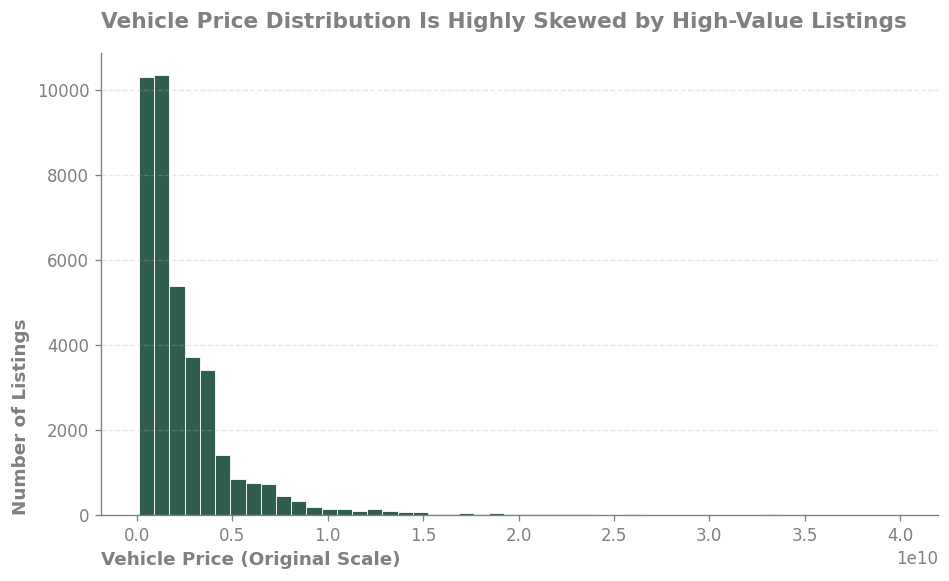

In [51]:
primary_color = "#2F5D50"
secondary_color = "#A6A6A6"

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    df_price['price'],
    bins=50,
    color=primary_color,
    edgecolor='white',
    linewidth=0.5
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.set_title(
    "Vehicle Price Distribution Is Highly Skewed by High-Value Listings",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="gray",
    pad=15
)

ax.set_xlabel(
    "Vehicle Price (Original Scale)",
    loc="left",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.set_ylabel(
    "Number of Listings",
    loc="bottom",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.tick_params(axis="x", colors="gray", labelsize=10)
ax.tick_params(axis="y", colors="gray", labelsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.savefig(FIGURES_DIR / "1.png")
plt.show()

The price distribution remains positively skewed even after removing unrealistic price records, indicating that the vehicle market contains a large number of mid/low-priced vehicles and a smaller segment of high-priced vehicles.

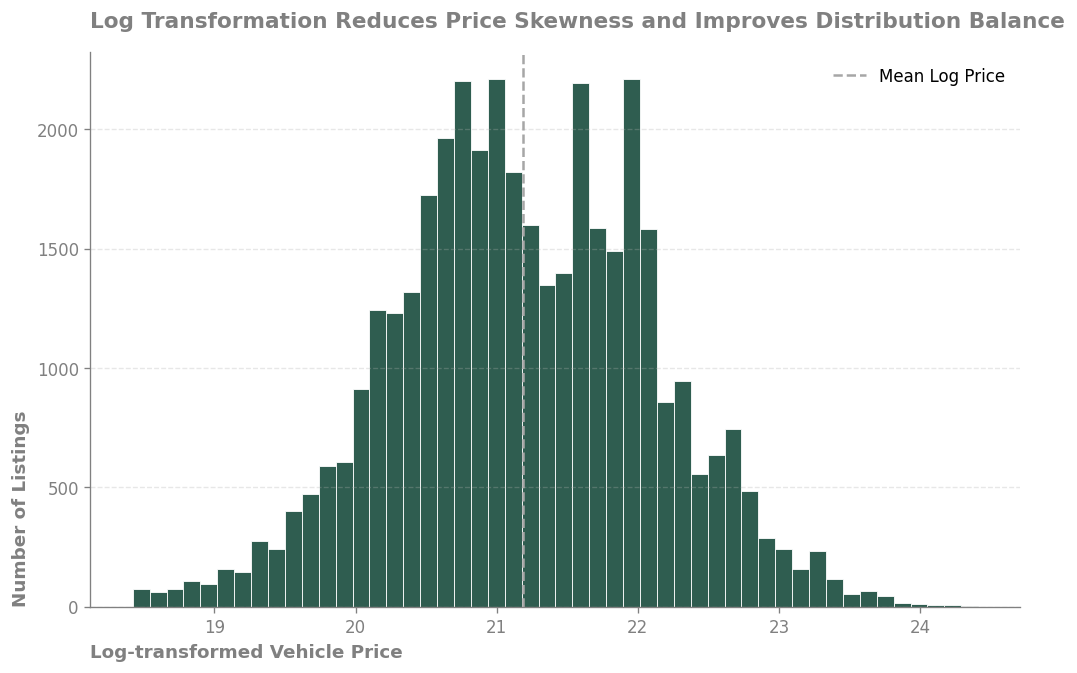

In [52]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    df_price['price_log'],
    bins=50,
    color=primary_color,
    edgecolor="white",
    linewidth=0.5
)

ax.axvline(
    df_price['price_log'].mean(),
    linestyle="--",
    linewidth=1.5,
    color=secondary_color,
    label="Mean Log Price"
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.set_title(
    "Log Transformation Reduces Price Skewness and Improves Distribution Balance",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="gray",
    pad=15
)

ax.set_xlabel(
    "Log-transformed Vehicle Price",
    loc="left",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.set_ylabel(
    "Number of Listings",
    loc="bottom",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.tick_params(axis="x", colors="gray", labelsize=10)
ax.tick_params(axis="y", colors="gray", labelsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.legend(frameon=False)

plt.savefig(FIGURES_DIR / "2.png")
plt.show()

### Key Findings

- Vehicle prices are highly right-skewed.
- Log transformation improves distribution symmetry.


In [53]:
df_price.head()

,url,title,price,year,address,external_information,authentication_status,description,mileage,fuel_type,...,interior_color,engine_capacity,powertrain,acceleration,combined_fuel_consumption,scraped_at,error,scraped_date,car_age,price_log
0,https://bama.ir/car/detail-rm9q02ew-hyundai-tu...,هیوندای، توسان,3.690000e+09,1396,تهران / پاسداران,https://bama.ir/car-reviews/hyundai/tucsonix35...,not_authenticated,فول شرکتی \n۵ گرمکن،۲ سرد کن،رادار نقطه کور و ...,99500,بنزینی,...,مشکی,2.0,4 سیلندر,11.8,8.3,2025-10-09 22:04:36,NaN,2025-10-09,8,22.028892
1,https://bama.ir/car/detail-i5ativ1y-bmw-x3-28-...,ب ام و، X3,5.500000e+09,1394,تبریز,https://bama.ir/car-reviews/bmw/x3-specs-978-3...,not_authenticated,زیر قیمت بازار ،،،رنگ خاص جاتوبا فول رادار ٫ ه...,72000,بنزینی,...,کرم,2.0,4 سیلندر توربوشارژ,6.5,7.3,2025-10-09 22:04:40,NaN,2025-10-09,10,22.428014
2,https://bama.ir/car/detail-fak8equz-peugeot-pa...,پژو، پارس,6.000000e+08,1393,لارستان,https://bama.ir/car-reviews/peugeot/pars-specs...,not_authenticated,با مانیتور و دوربین عقب و,165000,بنزینی,...,قهوه ای,1.6,4 سیلندر TU5,13.2,7.5,2025-10-09 22:04:45,NaN,2025-10-09,11,20.212440
3,https://bama.ir/car/detail-hwluitwe-peugeot-20...,پژو، 206 SD,6.700000e+08,1396,تبریز,https://bama.ir/car-reviews/peugeot/206sd-spec...,not_authenticated,NaN,93000,بنزینی,...,مشکی,1.6,4 سیلندر TU5,11.4,6.6,2025-10-09 22:04:50,NaN,2025-10-09,8,20.322788
4,https://bama.ir/car/detail-3zo2eijf-toyota-pra...,تویوتا، پرادو دو در,4.600000e+09,1385,تهران / شهید مطهری,NaN,NaN,NaN,289000,بنزینی,...,کرم,NaN,NaN,NaN,NaN,2025-10-09 22:04:55,NaN,2025-10-09,19,22.249322


## Vehicle Age vs Price


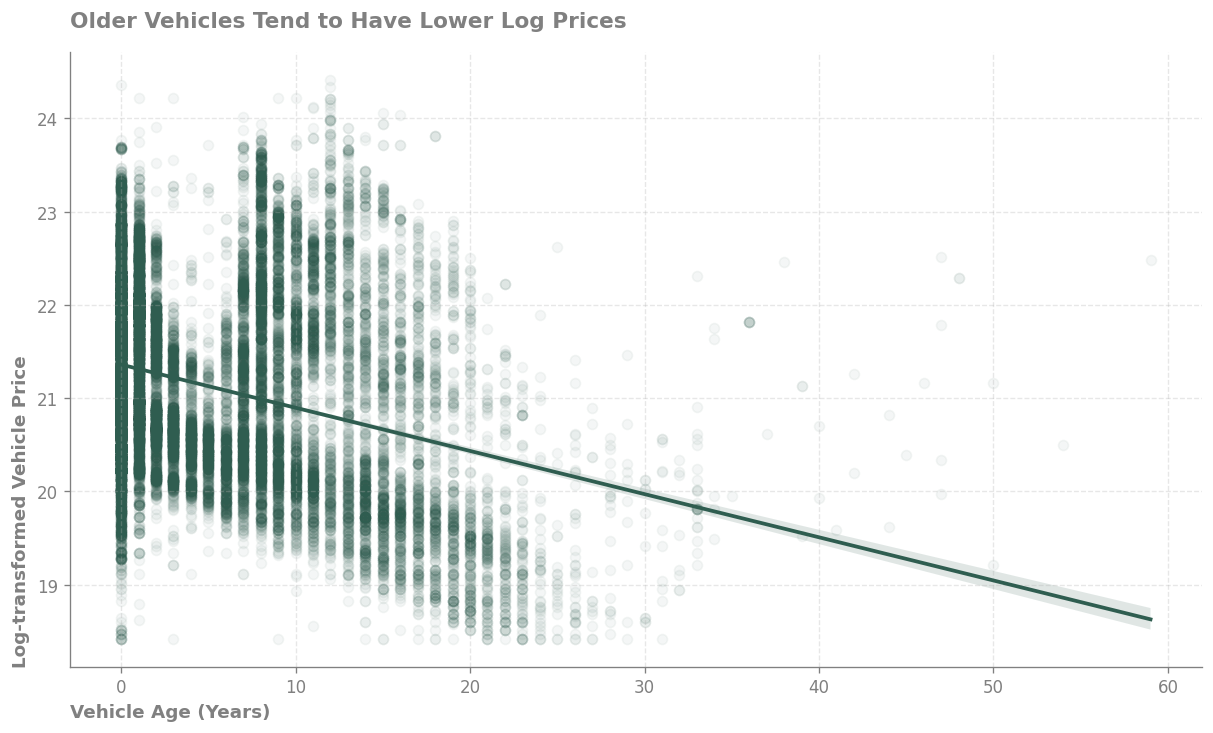

In [54]:
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

sns.regplot(
    data=df_price,
    x='car_age',
    y='price_log',
    scatter_kws={'alpha': 0.05},
    color=primary_color,
    ax=ax
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.set_title(
    "Older Vehicles Tend to Have Lower Log Prices",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="gray",
    pad=15
)

ax.set_xlabel(
    "Vehicle Age (Years)",
    loc="left",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.set_ylabel(
    "Log-transformed Vehicle Price",
    loc="bottom",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.tick_params(axis="x", colors="gray", labelsize=10)
ax.tick_params(axis="y", colors="gray", labelsize=10)

ax.grid(True, linestyle="--", alpha=0.3)

plt.savefig(FIGURES_DIR / "3.png")
plt.show()

In [55]:
df_price[['price_log','car_age']].corr()

,price_log,car_age
price_log,1.000000,-0.289761
car_age,-0.289761,1.000000


### Findings

- Vehicle age shows a negative correlation with log-transformed price (r = -0.29), indicating that older vehicles generally have lower prices. However, the moderate strength of this relationship suggests that other factors such as brand, mileage, transmission, and vehicle specifications also influence market prices.

## Mileage vs Price


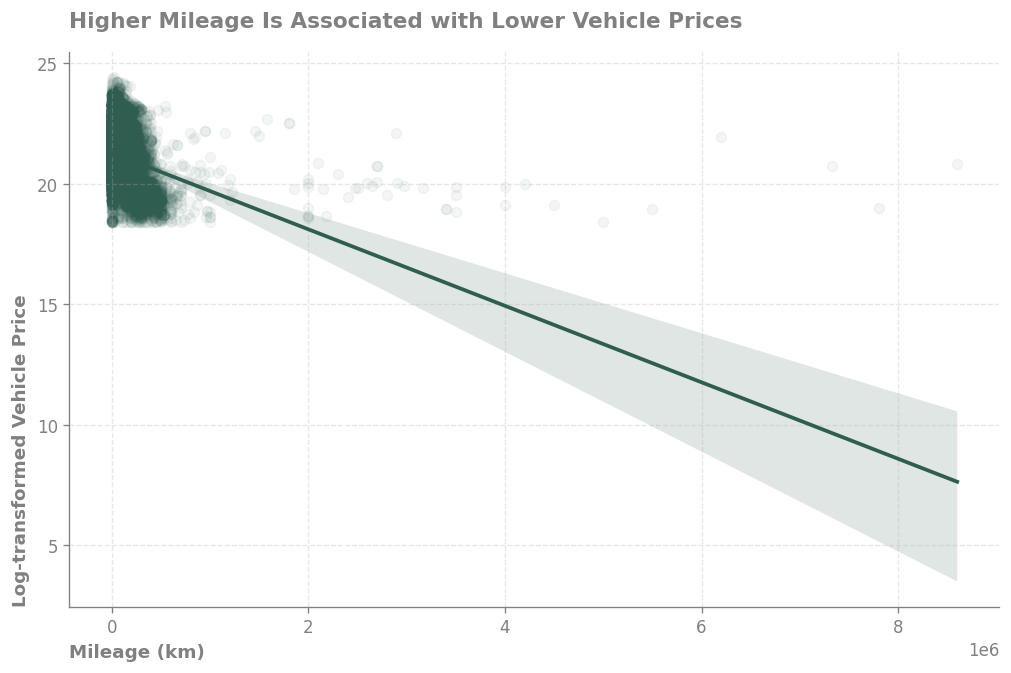

In [56]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=df_price,
    x='mileage',
    y='price_log',
    scatter_kws={'alpha': 0.05},
    color=primary_color,
    ax=ax
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.set_title(
    "Higher Mileage Is Associated with Lower Vehicle Prices",
    loc="left",
    fontsize=13,
    fontweight="bold",
    color="gray",
    pad=15
)

ax.set_xlabel(
    "Mileage (km)",
    loc="left",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.set_ylabel(
    "Log-transformed Vehicle Price",
    loc="bottom",
    fontsize=11,
    fontweight="bold",
    color="gray"
)

ax.tick_params(axis="x", colors="gray", labelsize=10)
ax.tick_params(axis="y", colors="gray", labelsize=10)

ax.grid(True, linestyle="--", alpha=0.3)

plt.savefig(FIGURES_DIR / "4.png")
plt.show()

In [57]:
df_price[['price_log','mileage']].corr()

,price_log,mileage
price_log,1.000000,-0.272293
mileage,-0.272293,1.000000


### Findings

- Mileage shows a negative relationship with log-transformed vehicle price (r = -0.27), indicating that vehicles with higher mileage generally have lower prices. However, the relatively moderate correlation suggests that mileage alone is not a dominant factor in price determination.

## Transmission Type vs Price

### Average Log Price by Transmission


In [58]:
df_price['transmission_en'] = df_price['transmission'].map({
    'اتوماتیک': 'Automatic',
    'دنده ای': 'Manual'
})

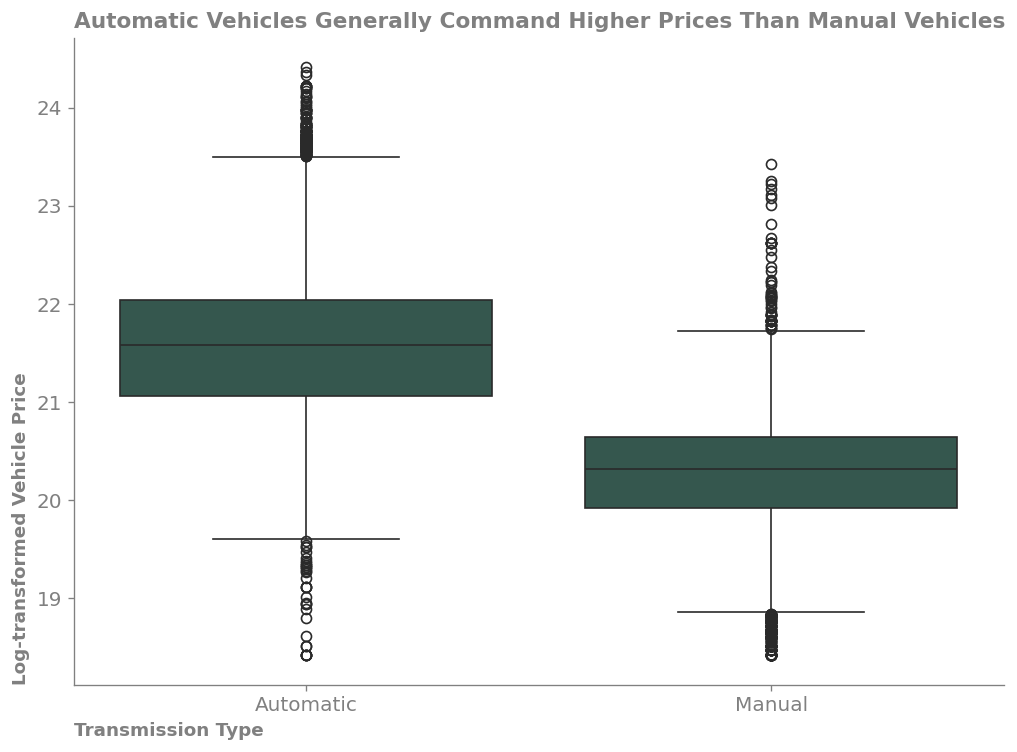

In [59]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(x='transmission_en', 
            y='price_log', 
            data=df_price, 
            color=primary_color,
            legend=False)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

plt.title(
    "Automatic Vehicles Generally Command Higher Prices Than Manual Vehicles",
    loc="left",
    weight="bold",
    color="gray",
    fontsize=13,
)
plt.xlabel("Transmission Type", 
           loc="left", 
           weight="bold", 
           color="gray", 
           fontsize=11)
plt.ylabel("Log-transformed Vehicle Price", 
           loc="bottom", 
           weight="bold", 
           color="gray", 
           fontsize=11)

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.savefig(FIGURES_DIR / "5.png")
plt.show()

In [60]:
df_price.groupby('transmission_en')['price_log'].mean()

transmission_en
Automatic    21.604028
Manual       20.244057
Name: price_log, dtype: float64

### Findings

- Automatic vehicles tend to have higher prices compared with manual vehicles. 
- This difference may be related to the fact that automatic transmissions are more common in newer and higher-segment vehicles.
- Both transmission categories contain high-value outliers, indicating the presence of premium vehicles in both groups.

## Fuel Type vs Price

### Average Log Price by Fuel Type


In [61]:
fuel_map = {
    'بنزینی':'Gasoline',
    'هیبریدی':'Hybrid',
    'برقی':'Electric',
    'دوگانه سوز':'Dual Fuel',
    'برقی با ژنراتور':'Electric + Generator',
    'پلاگین هیبرید':'Plug-in Hybrid',
    'دیزلی':'Diesel'
}

df_price['fuel_type_en'] = df_price['fuel_type'].map(fuel_map)

In [62]:
fuel_summary = (
    df_price.groupby('fuel_type_en')
    .agg(
        mean_price_log=('price_log','mean'),
        count=('price_log','count')
    )
    .sort_values('mean_price_log', ascending=False)
)

fuel_summary 

,mean_price_log,count
fuel_type_en,,
Electric + Generator,22.162379,351
Hybrid,22.038749,1832
Electric,22.009212,1377
Plug-in Hybrid,21.851090,61
Gasoline,21.135621,34081
Diesel,21.053294,29
Dual Fuel,19.887995,993


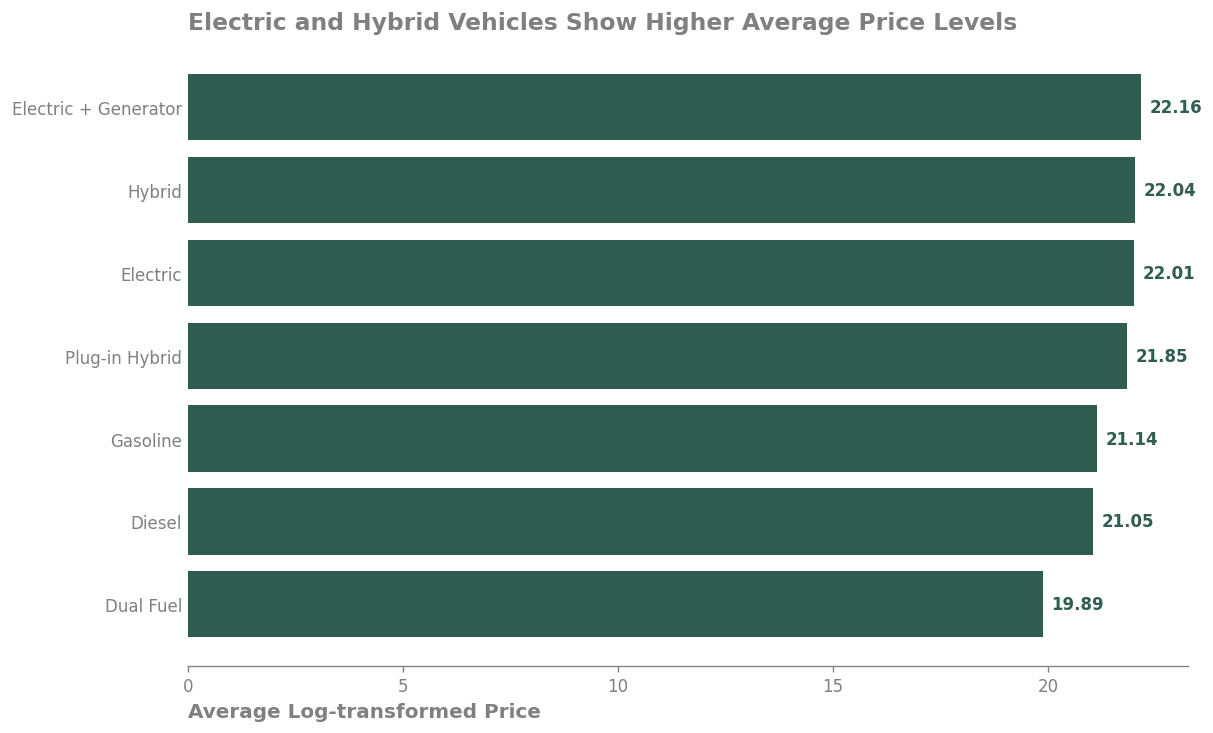

In [63]:
fuel_summary = fuel_summary.reset_index()

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

bars = ax.barh(
    fuel_summary["fuel_type_en"] ,
    fuel_summary["mean_price_log"],
    color=primary_color
)

ax.invert_yaxis()

ax.spines[["right", "left", "top"]].set_visible(False)
ax.spines["bottom"].set_color("gray")

ax.set_title(
    "Electric and Hybrid Vehicles Show Higher Average Price Levels",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="gray",
    pad=10
)

ax.set_xlabel(
    "Average Log-transformed Price",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color="gray",
)

for i, bar in enumerate(bars):
    width = bar.get_width()
    text_color = primary_color

    ax.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

ax.tick_params(axis="y", length=0, colors="gray")
ax.tick_params(axis="x", colors="gray")

plt.savefig(FIGURES_DIR / "6.png")
plt.show()

### Findings

- Electric and hybrid vehicles have the highest average log-transformed prices, while gasoline and dual-fuel vehicles show lower average prices. 
- This difference likely reflects the fact that electric and hybrid vehicles are generally newer, imported, and positioned in higher market segments. However, fuel type alone does not determine price, as other factors such as brand, model, age, and mileage also influence vehicle value.

## Manufacturing Year vs Price

### Average Log Price by Year


In [64]:
year_summary = (
    df_price
    .groupby('year')
    .agg(
        mean_price_log=('price_log','mean'),
        count=('price_log','count')
    )
    .sort_values('year')
)

year_summary.head(10)

,mean_price_log,count
year,,
1345,22.481124,1
1350,20.500122,1
1354,20.185329,2
1356,22.291882,2
1357,21.152212,4
1358,21.161521,1
1359,20.394762,1
1360,20.216590,2
1362,20.724764,2


In [65]:
year_summary_filtered = year_summary[
    year_summary['count'] >= 100
]

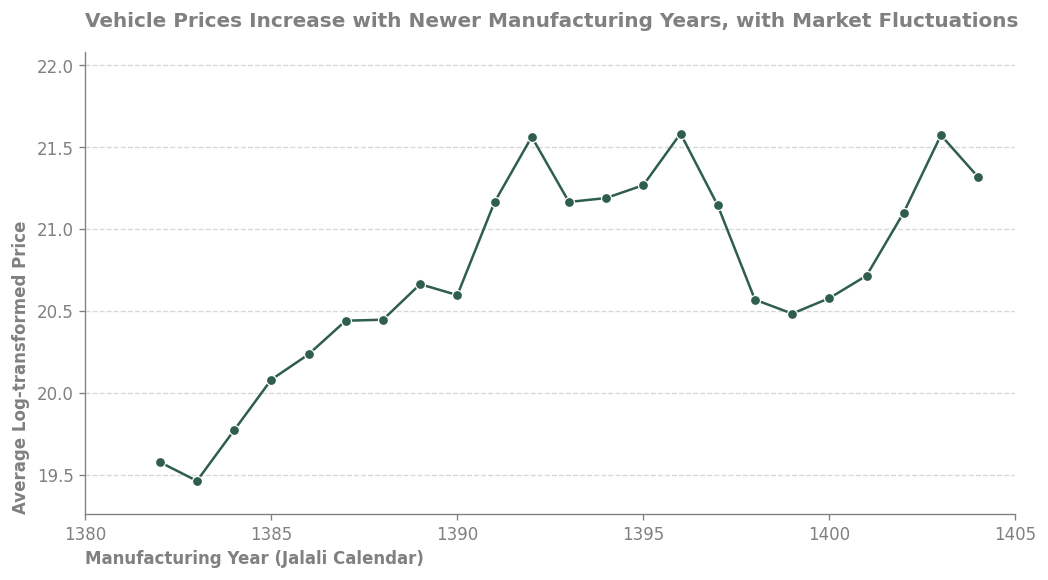

In [66]:
year_summary_filtered = year_summary_filtered.reset_index()

fig, ax = plt.subplots(figsize=(10, 5))

ax = sns.lineplot(
    data=year_summary_filtered,
    x="year",
    y="mean_price_log",
    marker="o",
    color=primary_color
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("gray")

ax.set_xlim(
    year_summary_filtered["year"].min() - 2,
    year_summary_filtered["year"].max() + 1
)

ax.set_ylim(
    year_summary_filtered["mean_price_log"].min() - 0.2,
    year_summary_filtered["mean_price_log"].max() + 0.5
)

ax.set_title(
    "Vehicle Prices Increase with Newer Manufacturing Years, with Market Fluctuations",
    loc="left",
    weight="bold",
    color="gray",
    fontsize=12,
    pad=15
)
ax.set_xlabel("Manufacturing Year (Jalali Calendar)"
              , loc="left", weight="bold", color="gray", fontsize=10)
ax.set_ylabel("Average Log-transformed Price",
               loc="bottom", weight="bold", color="gray", fontsize=10)

ax.tick_params(axis="x", colors="gray", labelsize=10)
ax.tick_params(axis="y", colors="gray", labelsize=10)

ax.grid(axis="y", linestyle="dashed", alpha=0.5)

plt.savefig(FIGURES_DIR / "7.png")
plt.show()

### Findings

- Vehicle manufacturing year shows an overall positive relationship with vehicle prices. 
- Newer vehicles generally have higher average prices compared with older vehicles.
- Trend is not perfectly linear, suggesting that factors such as vehicle brand, market segment, import status, and market conditions also affect vehicle prices.
- Average price is affected not only by vehicle age but also by the composition of vehicles available in each year.

## Brand Analysis

### Brand Extraction

Vehicle brands were extracted from the title column.


In [67]:
df_clean['title'].head(20)

0          هیوندای، توسان
1              ب ام و، X3
2               پژو، پارس
3             پژو، 206 SD
4     تویوتا، پرادو دو در
5              ب ام و، X4
6                  جک، S5
7              سمند، سورن
8           ام وی ام، X33
9              لیفان، X60
10             دوو، اسپرو
11    کیا، سراتو (مونتاژ)
12              پژو، پارس
13       هیوندای، سانتافه
14             رنو، داستر
15           تویوتا، ونزا
16               پژو، 206
17        سیتروئن، زانتیا
18             سمند، سورن
19        هیوندای، النترا
Name: title, dtype: object

In [68]:
df_clean['brand'] = df_clean['title'].str.split('،').str[0].str.strip()

df_clean['brand'].value_counts().head(30)

brand
پژو                  6105
تویوتا               4029
فونیکس               3952
کی ام سی             3279
ب ام و               2172
هیوندای              1843
پیش فروش کی ام سی    1683
ام وی ام             1655
فولکس                1578
دنا                  1498
نیسان                1444
سمند                 1346
بنز                  1227
کیا                  1196
رنو                  1128
تارا                 1006
پراید                 906
کوییک                 864
هایما                 828
فیدلیتی               810
اکستریم               784
مزدا                  694
شاهین                 693
چانگان                684
لاماری                673
لوکانو                655
جک                    604
لکسوس                 549
میتسوبیشی             505
هوندا                 500
Name: count, dtype: int64

In [69]:
df_clean[
    df_clean['brand'].str.contains(
        'پیش|فروش|حواله|اقساط',
        na=False
    )
]['brand'].value_counts()

brand
پیش فروش کی ام سی    1683
پیش فروش فونیکس       395
پیش فروش بی ای سی     319
حواله کی ام سی        235
پیش فروش ام وی ام     234
                     ... 
حواله رنو               1
پیش فروش دیگنیتی        1
پیش فروش اونترا         1
حواله مزدا              1
پیش فروش بنز            1
Name: count, Length: 92, dtype: int64

In [70]:
df_clean['brand_clean'] = df_clean['brand']

In [71]:
df_clean['brand_clean'] = (
    df_clean['brand_clean']
    .str.replace('پیش فروش ', '', regex=False)
    .str.replace('حواله ', '', regex=False)
    .str.strip()
)

In [72]:
df_clean['brand_clean'].value_counts().head(20)

brand_clean
پژو         6132
کی ام سی    5197
فونیکس      4493
تویوتا      4036
ب ام و      2219
ام وی ام    1937
هیوندای     1844
فولکس       1646
دنا         1534
نیسان       1518
سمند        1379
بنز         1237
کیا         1196
رنو         1138
تارا        1018
پراید        932
کوییک        891
اکستریم      861
هایما        849
فیدلیتی      819
Name: count, dtype: int64

### Brand Standardization

Listing-related prefixes such as:

- Pre-sale
- Voucher

were removed to avoid splitting the same brand into multiple categories.


### Top Brands by Number of Listings


In [73]:
brand_en_map = {
    'پژو': 'Peugeot',
    'کی ام سی': 'KMC',
    'فونیکس': 'Phoenix',
    'تویوتا': 'Toyota',
    'ب ام و': 'BMW',
    'ام وی ام': 'MVM',
    'هیوندای': 'Hyundai',
    'فولکس': 'Volkswagen',
    'دنا': 'Dena',
    'نیسان': 'Nissan',
    'سمند': 'Samand',
    'بنز': 'Mercedes-Benz',
    'کیا': 'Kia',
    'رنو': 'Renault',
    'تارا': 'Tara',
    'پراید': 'Pride',
    'کوییک': 'Quick',
    'اکستریم': 'Xtrim',
    'هایما': 'Haima',
    'فیدلیتی': 'Fidelity',
}

In [74]:
df_clean['brand_en'] = df_clean['brand_clean'].map(brand_en_map)

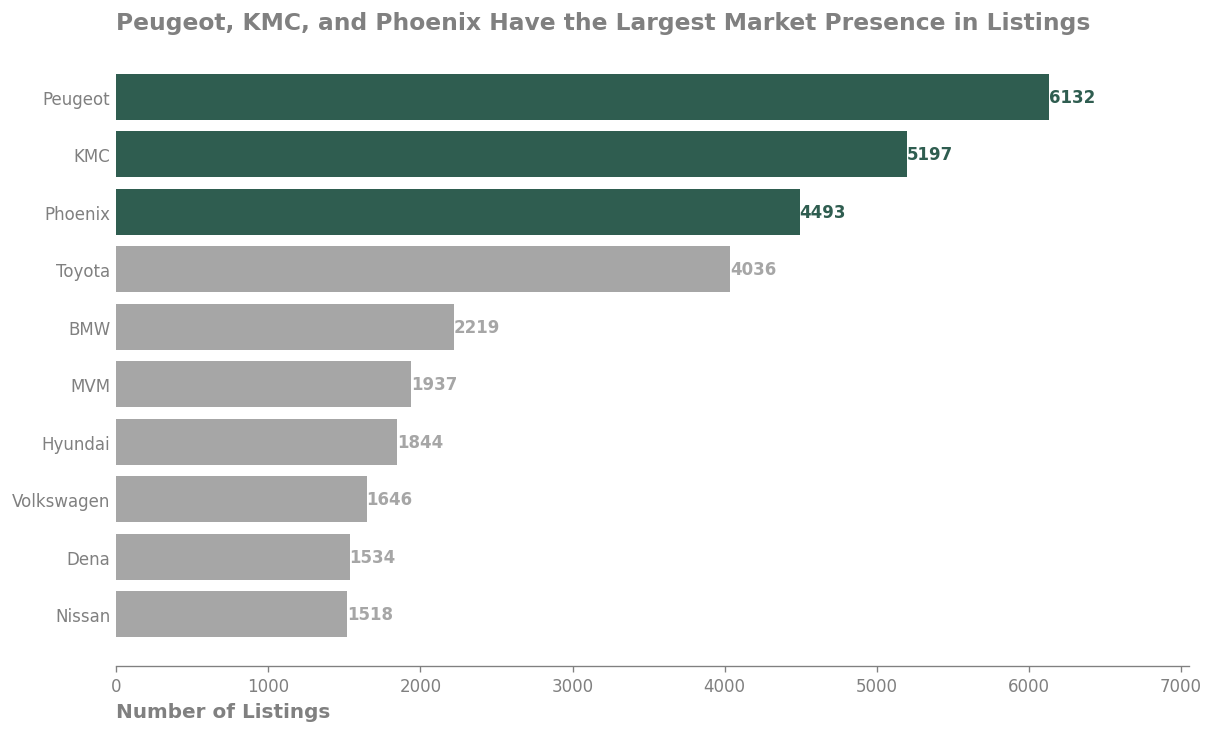

In [75]:
brand_count = (
    df_clean['brand_en']
    .value_counts()
    .head(10)
)

colors = [
    primary_color if i < 3 else secondary_color
    for i in range(len(brand_count.index))
]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

bars = ax.barh(
    brand_count.index,
    brand_count.values,
    color=colors
)

ax.invert_yaxis()

ax.spines[["right", "left", "top"]].set_visible(False)
ax.spines["bottom"].set_color("gray")

ax.set_title(
    "Peugeot, KMC, and Phoenix Have the Largest Market Presence in Listings",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="gray",
    pad=10
)

ax.set_xlabel(
    "Number of Listings",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color="gray",
)

max_x = brand_count.max()
ax.set_xlim(0, max_x * 1.15)

for i, bar in enumerate(bars):
    width = bar.get_width()
    text_color = primary_color if i < 3 else secondary_color

    ax.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

ax.tick_params(axis="y", length=0, colors="gray")
ax.tick_params(axis="x", colors="gray")

plt.savefig(FIGURES_DIR / "8.png")
plt.show()

### Findings

- Peugeot, KMC, and Phoenix have the highest number of listings in the dataset, indicating strong market presence on the platform. 
- However, listing frequency does not necessarily represent vehicle value or popularity, as it is affected by factors such as market demand, availability, and pricing segment.

### Top Brands by Average Price


In [76]:
df_price['brand'] = df_price['title'].str.split('،').str[0].str.strip()

In [77]:
df_price['brand_clean'] = (
    df_price['brand']
    .str.replace('پیش فروش ', '', regex=False)
    .str.replace('حواله ', '', regex=False)
    .str.strip()
)

In [78]:
brand_price = (
    df_price
    .groupby('brand_clean')
    .agg(
        mean_price_log=('price_log','mean'),
        count=('price_log','count')
    )
    .query('count >= 100')
    .sort_values('mean_price_log', ascending=False)
)

brand_price.head(20)

,mean_price_log,count
brand_clean,,
پورشه,23.246065,128
بنز,22.813939,522
ب ام و,22.775039,881
لکسوس,22.681282,265
آئودی,22.594374,173
تویوتا,22.373496,2019
میتسوبیشی,22.118004,274
بی وای دی,22.038745,249
فولکس,22.035091,852


In [79]:
brand_price_plot = (
    brand_price
    .head(10)
    .sort_values('mean_price_log', ascending=False)
)

In [80]:
brand_en_map = {
    'پورشه':'Porsche',
    'بنز':'Mercedes-Benz',
    'ب ام و':'BMW',
    'لکسوس':'Lexus',
    'آئودی':'Audi',
    'تویوتا':'Toyota',
    'میتسوبیشی':'Mitsubishi',
    'بی وای دی':'BYD',
    'فولکس':'Volkswagen',
    'اکستریم':'Xtrim'
}

In [81]:
brand_price_plot['brand_en'] = (
    brand_price_plot.index.map(brand_en_map)
)

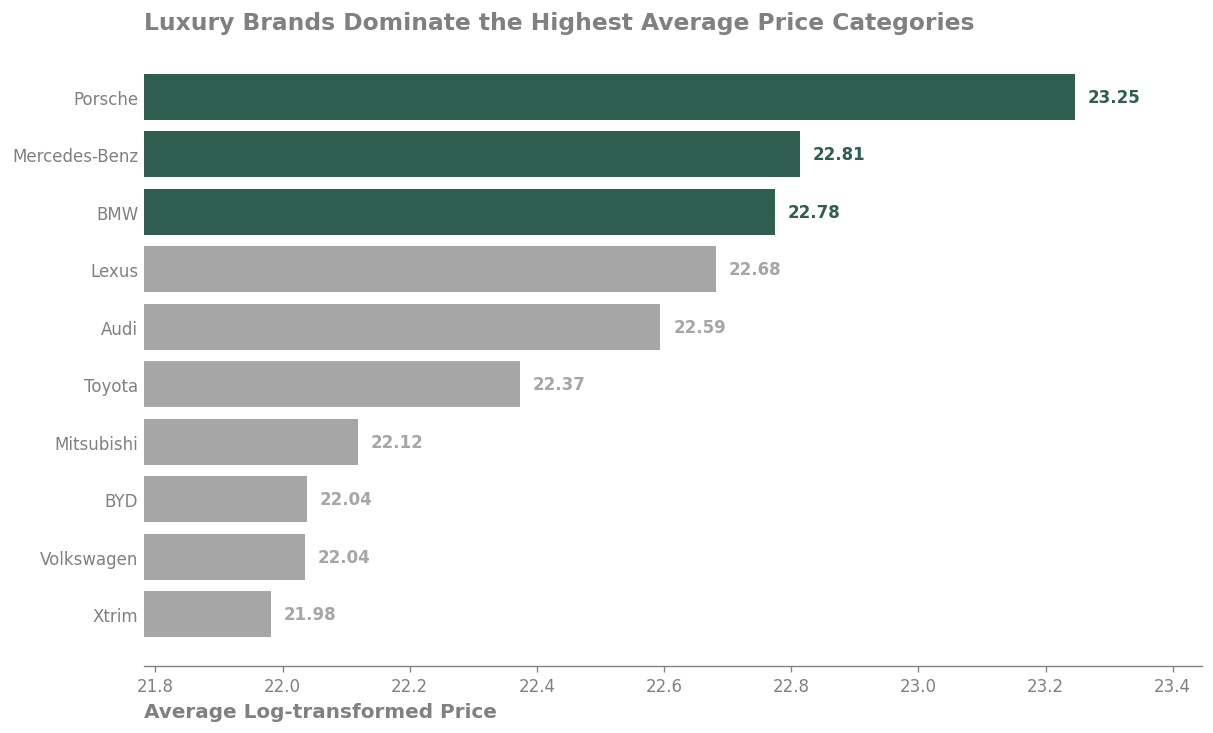

In [82]:
brand_price_plot=brand_price_plot.reset_index()

colors = [
    primary_color if i < 3 else secondary_color
    for i in range(len(brand_price_plot))
]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

bars = ax.barh(
    brand_price_plot['brand_en'],
    brand_price_plot['mean_price_log'],
    color=colors
)

ax.invert_yaxis()

ax.spines[["right", "left", "top"]].set_visible(False)
ax.spines["bottom"].set_color("gray")

ax.set_title(
    "Luxury Brands Dominate the Highest Average Price Categories",
    loc="left",
    fontsize=14,
    fontweight="bold",
    color="gray",
    pad=10
)

ax.set_xlabel(
    "Average Log-transformed Price",
    loc="left",
    fontsize=12,
    fontweight="bold",
    color="gray",
)

ax.set_xlim(
    brand_price_plot['mean_price_log'].min() - 0.2,
    brand_price_plot['mean_price_log'].max() + 0.2
)

for i, bar in enumerate(bars):
    width = bar.get_width()
    text_color = primary_color if i < 3 else secondary_color

    ax.text(
        width + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color=text_color
    )

ax.tick_params(axis="y", length=0, colors="gray")
ax.tick_params(axis="x", colors="gray")

plt.savefig(FIGURES_DIR / "9.png")
plt.show()

### Findings

- Brand analysis shows a clear difference in vehicle price positioning. 
- Premium brands such as Porsche, Mercedes-Benz, and BMW have the highest average prices in the dataset. 
- This indicates that brand positioning and market segment play an important role in vehicle pricing. 
- However, price differences are also influenced by other factors such as vehicle age, model, specifications, and availability.

## Key Insights

1. Brand is one of the strongest drivers of vehicle price.
2. Newer vehicles generally have higher prices.
3. Higher mileage is associated with lower prices.
4. Automatic vehicles tend to be more expensive than manual vehicles.
5. Electric and hybrid vehicles show higher average prices than conventional fuel vehicles.

---

## Limitations

- The exact currency unit of the price field was not explicitly documented.
- The dataset represents listing prices rather than actual transaction prices.
- Some listings contain incomplete technical specifications.
- Market conditions at the time of scraping may influence observed prices.

---

## Conclusion

This analysis explored the main factors associated with vehicle prices in the Bama.ir marketplace. Results indicate that brand, vehicle age, mileage, transmission type, and fuel type all contribute to price variation. Premium brands and newer vehicles consistently exhibit higher prices, while older and high-mileage vehicles tend to be more affordable.